# Training a Deep Network in PyTorch

### Prerequisite:

Download the data from [here](https://drive.google.com/file/d/1czcJcoG06uT7-xF2_3mr9uBV3qVVb6Tg/view)
and unzip it to `deeplearning_v2/dataset/dogs_and_cats/` folder.

In [3]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets, transforms

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
transform = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])
input_size = 32 * 32 * 3
data_root = "dogs_and_cats/dogs_and_cats"  # chứa các thư mục train/ valid/ test/
train_dataset = datasets.ImageFolder(f"{data_root}/train", transform=transform)
valid_dataset = datasets.ImageFolder(f"{data_root}/valid", transform=transform)

In [5]:
def split_data(dataset):
    imgs = []
    labels = []

    for x, y in dataset:
        imgs.append(x)
        labels.append(y)

    imgs = torch.stack(imgs, dim=0)
    labels = torch.as_tensor(labels, dtype=torch.long)

    return imgs, labels


train_data, train_label = split_data(train_dataset)
valid_data, valid_label = split_data(valid_dataset)

In [6]:
class MLP(torch.nn.Module):
    def __init__(self, input_size, *hidden_size):
        super().__init__()
        layers = []
        # Add hidden layers
        n_in = input_size
        for n_out in hidden_size:
            layers.append(torch.nn.Linear(n_in, n_out))
            layers.append(torch.nn.ReLU())
            n_in = n_out
        # Add the output layer
        layers.append(torch.nn.Linear(n_out, 1))

        # Use torch.nn.Sequential to create a small model,
        # where the layers are connected in a cascading way.
        # The order they are passed in the constructor
        self.network = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x.view(x.shape[0], -1))

In [10]:
n_epochs = 10
batch_size = 64

# Create the network
net = MLP(input_size, 100, 50, 50)

# Create the optimizer
optimizer = torch.optim.SGD(net.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)

# Create the loss
loss = torch.nn.BCEWithLogitsLoss()

# Start training
global_step = 0
train_loss_seq = []
train_accuracy_seq = []
valid_accuracy_seq = []
for epoch in range(n_epochs):
    # Shuffle the data
    indices_after_permutation = torch.randperm(train_data.size(0))

    # Iterate
    train_accuracy = []
    for it in range(0, len(indices_after_permutation) - batch_size + 1, batch_size):
        batch_samples = indices_after_permutation[it : it + batch_size]
        batch_data, batch_label = train_data[batch_samples], train_label[batch_samples]
        batch_label = batch_label.view(-1, 1)

        # Compute the loss
        o = net(batch_data)
        loss_train = loss(o, batch_label.float())

        print(f"[Epoch {epoch}][{it}/{len(indices_after_permutation)}] train/loss: {loss_train}")
        train_loss_seq.append(loss_train)
        # Compute the accuracy
        train_pred = o > 0
        train_accuracy.extend((train_pred.long() == batch_label).cpu().detach().numpy())

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        # Increase the global step
        global_step += 1

    # Evaluate the model
    valid_accuracy = []
    for it in range(0, len(valid_dataset), batch_size):
        batch_data, batch_label = valid_data[it : it + batch_size], valid_label[it : it + batch_size]
        batch_label = batch_label.view(-1, 1)
        valid_pred = net(batch_data) > 0
        valid_accuracy.extend((valid_pred.long() == batch_label).cpu().detach().numpy())

    print(f"[Epoch {epoch}] train/accuracy: {np.mean(train_accuracy)}")
    print(f"[Epoch {epoch}] valid/accuracy: {np.mean(valid_accuracy)}")
    train_accuracy_seq.append(np.mean(train_accuracy))
    valid_accuracy_seq.append(np.mean(valid_accuracy))

[Epoch 0][0/19567] train/loss: 0.6968526840209961
[Epoch 0][64/19567] train/loss: 0.6949276924133301
[Epoch 0][128/19567] train/loss: 0.6945724487304688
[Epoch 0][192/19567] train/loss: 0.6929676532745361
[Epoch 0][256/19567] train/loss: 0.6935938596725464
[Epoch 0][320/19567] train/loss: 0.6933649778366089
[Epoch 0][384/19567] train/loss: 0.693206250667572
[Epoch 0][448/19567] train/loss: 0.6947439908981323
[Epoch 0][512/19567] train/loss: 0.6929550766944885
[Epoch 0][576/19567] train/loss: 0.6920563578605652
[Epoch 0][640/19567] train/loss: 0.6941179037094116
[Epoch 0][704/19567] train/loss: 0.6954556107521057
[Epoch 0][768/19567] train/loss: 0.6973726749420166
[Epoch 0][832/19567] train/loss: 0.6924019455909729
[Epoch 0][896/19567] train/loss: 0.6945560574531555
[Epoch 0][960/19567] train/loss: 0.6912321448326111
[Epoch 0][1024/19567] train/loss: 0.693770170211792
[Epoch 0][1088/19567] train/loss: 0.6898171901702881
[Epoch 0][1152/19567] train/loss: 0.6959314942359924
[Epoch 0][1216

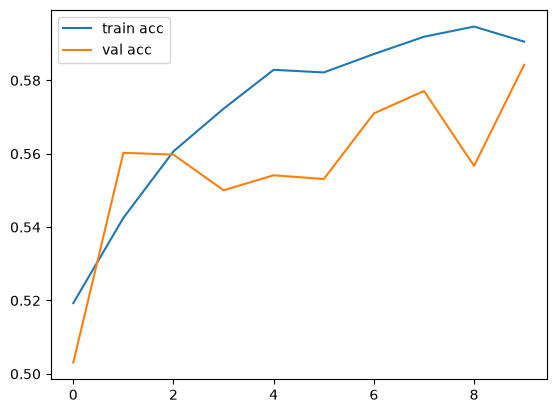

In [11]:
plt.plot(range(n_epochs), train_accuracy_seq, label="train acc")
plt.plot(range(n_epochs), valid_accuracy_seq, label="val acc")
plt.legend()
plt.show()

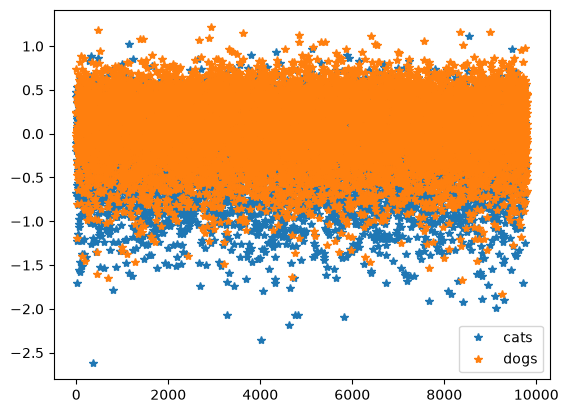

In [12]:
plt.plot(net(train_data[train_label == 0]).view(-1).cpu().detach().numpy(), "*", label="cats")
plt.plot(net(train_data[train_label == 1]).view(-1).cpu().detach().numpy(), "*", label="dogs")
plt.legend()
plt.show()

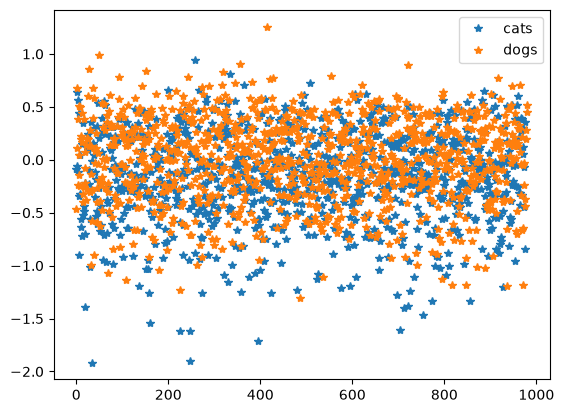

In [13]:
plt.plot(net(valid_data[valid_label == 0]).view(-1).cpu().detach().numpy(), "*", label="cats")
plt.plot(net(valid_data[valid_label == 1]).view(-1).cpu().detach().numpy(), "*", label="dogs")
plt.legend()
plt.show()